# AH2179 Project
## Multimodal Visual Place Recognition for Public Transit
### Vehicle Localisation in GNSS Denied Environments
#### Authors: *Erik Månsson & Nils Wiklund*
#### Dataset Access: Dataset and model weights available on request.
#### AI Declaration: Gemini Flash 3.5, 3.7, 3.8, and 3.1 Pro has been used for code generation in this project.


In [ ]:
#@title Imports and Installs
!pip install xformers
!pip install ultralytics

import os
import glob
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import plotly.express as px
import plotly.graph_objects as go
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm
from torchvision import transforms
from torchvision.io import read_image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from typing import Dict, Tuple, Optional, List
from scipy.spatial import KDTree
from google.colab import drive
from ultralytics import YOLO

drive.mount('/content/drive')

  Using cached xformers-0.0.35-py39-none-manylinux_2_28_x86_64.whl.metadata (1.2 kB)
Using cached xformers-0.0.35-py39-none-manylinux_2_28_x86_64.whl (3.3 MB)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#@title Multi Route Spatial Dataset
class MultiRouteSpatialDataset(Dataset):
    """
    Aggregates multiple MiSensorKit recordings, establishes a shared Cartesian frame,
    and indexes frames spatially using a k-d tree to yield multi-view spatial clusters.
    """
    def __init__(
        self,
        route_dirs: List[str],
        global_origin: Optional[Tuple[float, float]] = None,
        samples_per_place: int = 4,
        max_spatial_radius: float = 15.0,
        enforce_distinct_routes: bool = True,
        target_depth_shape: Optional[Tuple[int, int]] = None
    ):
        super().__init__()
        self.route_dirs = route_dirs
        self.samples_per_place = samples_per_place
        self.max_spatial_radius = max_spatial_radius
        self.enforce_distinct_routes = enforce_distinct_routes
        self.target_depth_shape = target_depth_shape
        self.EARTH_RADIUS = 6378137.0
        self.rgb_transform = transforms.ConvertImageDtype(torch.float32)

        self.frame_index: List[Dict] = []
        self._discover_and_align_routes(global_origin)

        self.coords_array = np.array([f['coords'][:2] for f in self.frame_index], dtype=np.float32)
        self.spatial_tree = KDTree(self.coords_array)

    def _discover_and_align_routes(self, global_origin: Optional[Tuple[float, float]]):
        if global_origin is None:
            first_gps_file = sorted(glob.glob(os.path.join(self.route_dirs[0], 'gps', '*.json')))[0]
            with open(first_gps_file, 'r') as f:
                loc_data = json.load(f)
            self.origin_lat = math.radians(loc_data['latitude'])
            self.origin_lon = math.radians(loc_data['longitude'])
        else:
            self.origin_lat = math.radians(global_origin[0])
            self.origin_lon = math.radians(global_origin[1])

        for route_id, route_dir in enumerate(self.route_dirs):
            rgb_files = sorted(glob.glob(os.path.join(route_dir, 'rgb', '*.jpg')))
            depth_files = sorted(glob.glob(os.path.join(route_dir, 'depth', '*.bin')))
            cam_files = sorted(glob.glob(os.path.join(route_dir, 'camera', '*.json')))
            gps_files = sorted(glob.glob(os.path.join(route_dir, 'gps', '*.json')))

            if not (len(rgb_files) == len(depth_files) == len(cam_files) == len(gps_files)):
                raise ValueError(f"Inconsistent frame counts in directory: {route_dir}")

            with open(cam_files[0], 'r') as f:
                cam_data = json.load(f)
            if 'depth_height' in cam_data and 'depth_width' in cam_data:
                depth_shape = (cam_data['depth_height'], cam_data['depth_width'])
            else:
                depth_bytes = os.path.getsize(depth_files[0]) // 2
                depth_shape = (int(np.sqrt(depth_bytes * 3 / 4)), int(np.sqrt(depth_bytes * 4 / 3)))

            for i in range(len(rgb_files)):
                with open(gps_files[i], 'r') as f:
                    loc = json.load(f)

                lat = math.radians(loc['latitude'])
                lon = math.radians(loc['longitude'])
                alt = loc.get('altitude_m', 0.0)

                # Equirectangular projection onto unified Cartesian plane
                x = self.EARTH_RADIUS * (lon - self.origin_lon) * math.cos(self.origin_lat)
                y = self.EARTH_RADIUS * (lat - self.origin_lat)
                z = alt

                if i % 50 == 0:
                    print(f"Indexing route {route_id} metadata: frame {i}...", end="\r", flush=True)

                self.frame_index.append({
                    'route_id': route_id,
                    'rgb_path': rgb_files[i],
                    'depth_path': depth_files[i],
                    'cam_path': cam_files[i],
                    'depth_shape': depth_shape,
                    'coords': (x, y, z)
                })

    def __len__(self) -> int:
        return len(self.frame_index)

    def _load_frame(self, meta: Dict) -> Tuple[torch.Tensor, torch.Tensor, Dict[str, torch.Tensor], torch.Tensor]:
        rgb = self.rgb_transform(read_image(meta['rgb_path']))

        depth_np = np.fromfile(meta['depth_path'], dtype=np.uint16).reshape(meta['depth_shape'])
        depth = torch.from_numpy(depth_np.astype(np.float32)).unsqueeze(0).unsqueeze(0) / 1000.0

        # Dynamic parameterization replacing hardcoded dimension definitions
        if self.target_depth_shape is not None and meta['depth_shape'] != self.target_depth_shape:
            depth = F.interpolate(depth, size=self.target_depth_shape, mode='nearest-exact')
        depth = depth.squeeze(0)

        with open(meta['cam_path'], 'r') as f:
            cam_data = json.load(f)

        current_shape = self.target_depth_shape if self.target_depth_shape else meta['depth_shape']

        intrinsics = {
            'fx': torch.tensor(cam_data.get('fx', 1.0), dtype=torch.float32),
            'fy': torch.tensor(cam_data.get('fy', 1.0), dtype=torch.float32),
            'cx': torch.tensor(cam_data.get('cx', current_shape[1] / 2.0), dtype=torch.float32),
            'cy': torch.tensor(cam_data.get('cy', current_shape[0] / 2.0), dtype=torch.float32)
        }
        coords = torch.tensor(meta['coords'], dtype=torch.float32)
        return rgb, depth, intrinsics, coords

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, Dict[str, torch.Tensor], torch.Tensor]:
        anchor_meta = self.frame_index[idx]
        anchor_pos = np.array(anchor_meta['coords'][:2])
        candidate_indices = self.spatial_tree.query_ball_point(anchor_pos, r=self.max_spatial_radius)

        selected_indices = [idx]
        if self.enforce_distinct_routes:
            for c_idx in candidate_indices:
                if len(selected_indices) >= self.samples_per_place:
                    break
                if self.frame_index[c_idx]['route_id'] != anchor_meta['route_id'] and c_idx not in selected_indices:
                    selected_indices.append(c_idx)

        if len(selected_indices) < self.samples_per_place:
            for c_idx in candidate_indices:
                if len(selected_indices) >= self.samples_per_place:
                    break
                if c_idx not in selected_indices:
                    selected_indices.append(c_idx)

        while len(selected_indices) < self.samples_per_place:
            selected_indices.append(selected_indices[0])

        rgbs, depths, coords_list = [], [], []
        fxs, fys, cxs, cys = [], [], [], []

        for f_idx in selected_indices:
            r, d, k, c = self._load_frame(self.frame_index[f_idx])
            rgbs.append(r)
            depths.append(d)
            coords_list.append(c)
            fxs.append(k['fx'])
            fys.append(k['fy'])
            cxs.append(k['cx'])
            cys.append(k['cy'])

        cluster_rgb = torch.stack(rgbs, dim=0)
        cluster_depth = torch.stack(depths, dim=0)
        cluster_coords = torch.stack(coords_list, dim=0)
        cluster_intrinsics = {
            'fx': torch.stack(fxs),
            'fy': torch.stack(fys),
            'cx': torch.stack(cxs),
            'cy': torch.stack(cys)
        }

        return cluster_rgb, cluster_depth, cluster_intrinsics, cluster_coords

In [ ]:
#@title RGB-D Point Transformer Architecture
class DINOv2FeatureExtractor(nn.Module):
    def __init__(self, model_name: str = 'dinov2_vits14', freeze: bool = True):
        super().__init__()
        self.backbone = torch.hub.load('/content/dinov2', model_name, source='local')
        self.embed_dim = self.backbone.embed_dim
        self.patch_size = self.backbone.patch_size

        if freeze:
            for param in self.backbone.parameters():
                param.requires_grad = False
            self.backbone.eval()

    def forward(self, rgb: torch.Tensor, target_hw: Tuple[int, int]) -> torch.Tensor:
        b, _, h_orig, w_orig = rgb.shape
        new_h = (h_orig // self.patch_size) * self.patch_size
        new_w = (w_orig // self.patch_size) * self.patch_size

        if (new_h, new_w) != (h_orig, w_orig):
            rgb = F.interpolate(rgb, size=(new_h, new_w), mode='bilinear', align_corners=False)

        mean = torch.tensor([0.485, 0.456, 0.406], device=rgb.device).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225], device=rgb.device).view(1, 3, 1, 1)
        rgb_norm = (rgb - mean) / std

        features_dict = self.backbone.forward_features(rgb_norm)
        patch_tokens = features_dict['x_norm_patchtokens']
        grid_h, grid_w = new_h // self.patch_size, new_w // self.patch_size
        patch_tokens = patch_tokens.transpose(1, 2).reshape(b, self.embed_dim, grid_h, grid_w)

        return F.interpolate(patch_tokens, size=target_hw, mode='bilinear', align_corners=False)


class RGBDPointLifter(nn.Module):
    def __init__(self, min_depth: float = 0.1, max_depth: float = 10.0, num_samples: int = 2048):
        super().__init__()
        self.min_depth = min_depth
        self.max_depth = max_depth
        self.num_samples = num_samples

    def forward(self, depth: torch.Tensor, features: torch.Tensor, intrinsics: Dict[str, torch.Tensor], coords: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        b, _, h, w = depth.shape
        device = depth.device

        v_grid, u_grid = torch.meshgrid(
            torch.arange(h, device=device, dtype=torch.float32),
            torch.arange(w, device=device, dtype=torch.float32),
            indexing='ij'
        )

        batch_xyz, batch_feats = [], []

        for i in range(b):
            fx, fy = intrinsics['fx'][i], intrinsics['fy'][i]
            cx, cy = intrinsics['cx'][i], intrinsics['cy'][i]

            d = depth[i, 0]
            valid_mask = (d > self.min_depth) & (d < self.max_depth)

            u_valid, v_valid, d_valid = u_grid[valid_mask], v_grid[valid_mask], d[valid_mask]
            x_cam, y_cam = (u_valid - cx) * d_valid / fx, (v_valid - cy) * d_valid / fy

            xyz_global = torch.stack([x_cam, y_cam, d_valid], dim=-1) + coords[i].unsqueeze(0)
            valid_feats = features[i].permute(1, 2, 0)[valid_mask]

            num_points = xyz_global.shape[0]
            if num_points >= self.num_samples:
                indices = torch.randperm(num_points, device=device)[:self.num_samples]
            elif num_points > 0:
                indices = torch.randint(0, num_points, (self.num_samples,), device=device)
            else:
                xyz_global = torch.zeros((self.num_samples, 3), device=device)
                valid_feats = torch.zeros((self.num_samples, features.shape[1]), device=device)
                indices = torch.arange(self.num_samples, device=device)

            batch_xyz.append(xyz_global[indices])
            batch_feats.append(valid_feats[indices])

        return torch.stack(batch_xyz, dim=0), torch.stack(batch_feats, dim=0)


class PointTransformerVectorAttention(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, k_neighbors: int = 16):
        super().__init__()
        self.k = k_neighbors
        self.linear_q = nn.Linear(in_channels, out_channels, bias=False)
        self.linear_k = nn.Linear(in_channels, out_channels, bias=False)
        self.linear_v = nn.Linear(in_channels, out_channels, bias=False)

        self.pos_mlp = nn.Sequential(
            nn.Linear(3, out_channels), nn.ReLU(inplace=True), nn.Linear(out_channels, out_channels)
        )
        self.vector_attn_mlp = nn.Sequential(
            nn.Linear(out_channels, out_channels), nn.ReLU(inplace=True), nn.Linear(out_channels, out_channels)
        )
        self.proj_out = nn.Linear(out_channels, out_channels)

    def forward(self, xyz: torch.Tensor, features: torch.Tensor, knn_idx: torch.Tensor) -> torch.Tensor:
        b, n, _ = xyz.shape

        idx_base = torch.arange(b, device=xyz.device).view(-1, 1, 1) * n
        flat_idx = (knn_idx + idx_base).view(-1)

        knn_xyz = xyz.view(b * n, 3)[flat_idx].view(b, n, self.k, 3)
        delta = self.pos_mlp(xyz.unsqueeze(2) - knn_xyz)

        q = self.linear_q(features).unsqueeze(2)
        knn_feats = features.view(b * n, -1)[flat_idx].view(b, n, self.k, -1)
        k, v = self.linear_k(knn_feats), self.linear_v(knn_feats)

        attn_weights = F.softmax(self.vector_attn_mlp(q - k + delta), dim=2)
        return self.proj_out(torch.sum(attn_weights * (v + delta), dim=2))


class JointPointTransformerPlaceEncoder(nn.Module):
    def __init__(self, dino_dim: int = 384, latent_dim: int = 256, k_neighbors: int = 16, output_dim: int = 512):
        super().__init__()
        self.input_proj = nn.Linear(dino_dim, latent_dim)
        self.block1 = PointTransformerVectorAttention(latent_dim, latent_dim, k_neighbors=k_neighbors)
        self.norm1 = nn.LayerNorm(latent_dim)
        self.block2 = PointTransformerVectorAttention(latent_dim, latent_dim, k_neighbors=k_neighbors)
        self.norm2 = nn.LayerNorm(latent_dim)
        self.gem_p = nn.Parameter(torch.ones(1) * 3.0)
        self.head = nn.Sequential(nn.Linear(latent_dim, output_dim), nn.LayerNorm(output_dim))

    def forward(self, xyz: torch.Tensor, features: torch.Tensor) -> torch.Tensor:
        # --- OPTIMIZATION: Single-pass, unchunked KNN computation ---
        # Executes instantly as a single CUDA kernel and reuses the geometry mapping
        dist_mat = torch.cdist(xyz, xyz)
        _, knn_idx = torch.topk(dist_mat, k=self.block1.k, dim=-1, largest=False)
        # ------------------------------------------------------------

        h = self.input_proj(features)

        # Pass the pre-computed indices into the attention blocks
        h = h + self.block1(xyz, self.norm1(h), knn_idx)
        h = h + self.block2(xyz, self.norm2(h), knn_idx)

        pooled = torch.mean(torch.clamp(h, min=1e-6) ** self.gem_p, dim=1) ** (1.0 / self.gem_p)
        place_emb = self.head(pooled)
        return place_emb, F.normalize(place_emb, p=2, dim=-1)

In [ ]:
#@title Semantic Masker
class SemanticMasker(nn.Module):
    def __init__(self, model_name='yolov8n-seg.pt', device='cuda', conf_threshold=0.25):
        super().__init__()
        # Load the YOLOv8 segmentation model
        self.model = YOLO(model_name)
        self.device = device
        self.conf_threshold = conf_threshold

        # COCO class IDs for common dynamic objects to mask out:
        # 0: person, 1: bicycle, 2: car, 3: motorcycle, 5: bus, 7: truck
        self.dynamic_classes = [0, 1, 2, 3, 5, 7]

    def forward(self, rgb: torch.Tensor, depth: torch.Tensor) -> torch.Tensor:
        """
        rgb: (B, 3, H, W) normalized image tensor
        depth: (B, 1, H, W) depth map
        Returns masked depth map where dynamic objects are set to 0.
        """
        B, _, H, W = rgb.shape
        masked_depth = depth.clone()

        # Process each image in the batch
        for i in range(B):
            # Convert tensor image back to uint8 numpy for YOLO
            # Assuming rgb is roughly in [0, 1] or requires un-normalization if transformed heavily
            # In our dataset, rgb_transform uses ConvertImageDtype(torch.float32) which puts it in [0, 1]
            img_np = (rgb[i].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

            # Run inference
            results = self.model(img_np, verbose=False, conf=self.conf_threshold)
            result = results[0]

            if result.masks is not None:
                # Get masks and classes
                masks = result.masks.data.cpu().numpy() # (N, H, W)
                classes = result.boxes.cls.cpu().numpy()

                # Create a combined mask for all dynamic objects
                combined_mask = np.zeros((H, W), dtype=bool)

                for mask, cls in zip(masks, classes):
                    if int(cls) in self.dynamic_classes:
                        # YOLO masks might be different size, resize if needed
                        if mask.shape != (H, W):
                            import cv2
                            mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)
                        combined_mask = combined_mask | (mask > 0.5)

                # Apply mask to depth (set to 0 where dynamic object exists)
                # The lifter uses min_depth (e.g., 0.1 or 0.2), so 0 is ignored.
                combined_mask_tensor = torch.from_numpy(combined_mask).to(self.device)
                masked_depth[i, 0][combined_mask_tensor] = 0.0

        return masked_depth

In [ ]:
def preextract_geometry_with_masking(
    dataloader: DataLoader,
    feature_extractor: torch.nn.Module,
    point_lifter: torch.nn.Module,
    semantic_masker: torch.nn.Module,
    device: str = 'cuda'
) -> tuple:
    """
    Extracts geometry with dynamic semantic masking.
    """
    feature_extractor.eval()
    point_lifter.eval()
    # semantic_masker does not need eval() as YOLO handles it internally

    all_xyz = []
    all_feats = []
    all_coords = []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Extracting Global Geometry (Masked)"):
            rgb, depth, intrinsics, coords = batch

            # Dynamically flatten 5D cluster batches (B, S, C, H, W) to 4D (B*S, C, H, W)
            if rgb.dim() == 5:
                b, s, c, h, w = rgb.shape
                rgb = rgb.view(b * s, c, h, w)
                depth = depth.view(b * s, 1, depth.shape[-2], depth.shape[-1])
                coords = coords.view(b * s, -1)
                intrinsics = {k: v.view(b * s) for k, v in intrinsics.items()}

            rgb = rgb.to(device)
            depth = depth.to(device)
            coords = coords.to(device)
            intrinsics_dev = {k: v.to(device) for k, v in intrinsics.items()}

            # 0. Apply Semantic Masking (zero out depth for dynamic objects)
            depth_masked = semantic_masker(rgb, depth)

            # 1. Extract dense visual patches
            _, _, target_h, target_w = depth_masked.shape
            with torch.autocast(device_type=device, dtype=torch.float16):
                patch_tokens = feature_extractor(rgb, target_hw=(target_h, target_w))

            # 2. Lift to 3D spatial coordinates (using masked depth)
            batch_xyz, batch_feats = point_lifter(depth_masked, patch_tokens, intrinsics_dev, coords)

            # 3. Cast to float16 and move to CPU RAM
            all_xyz.append(batch_xyz.half().cpu())
            all_feats.append(batch_feats.half().cpu())
            all_coords.append(coords.cpu())

    db_xyz = torch.cat(all_xyz, dim=0)
    db_feats = torch.cat(all_feats, dim=0)
    db_coords = torch.cat(all_coords, dim=0)

    print(f"\nExtraction Complete.")
    print(f"Resident Tensor Size (XYZ):   {db_xyz.element_size() * db_xyz.nelement() / 1e6:.2f} MB")
    print(f"Resident Tensor Size (Feats): {db_feats.element_size() * db_feats.nelement() / 1e6:.2f} MB")

    return db_xyz, db_feats, db_coords

In [ ]:
class SemanticMaskedDatasetWrapper(Dataset):
    """
    Wraps the MultiRouteSpatialDataset to apply YOLOv8 semantic masking on the fly.
    """
    def __init__(self, base_dataset: Dataset, semantic_masker: torch.nn.Module):
        self.base_dataset = base_dataset
        self.semantic_masker = semantic_masker

    def __len__(self) -> int:
        return len(self.base_dataset)

    def __getitem__(self, idx: int):
        # Fetch the spatial cluster from the base dataset
        # Shapes: rgb (S, 3, H, W), depth (S, 1, H, W)
        cluster_rgb, cluster_depth, cluster_intrinsics, cluster_coords = self.base_dataset[idx]

        # Apply the YOLOv8-seg mask to zero out dynamic objects in the depth map
        # The base dataset returns a cluster of 'S' frames, which acts as the batch size 'B'
        # for the semantic_masker's forward pass.
        with torch.no_grad():
            masked_depth = self.semantic_masker(cluster_rgb, cluster_depth)

        return cluster_rgb, masked_depth.cpu(), cluster_intrinsics, cluster_coords

In [ ]:
#@title Spatial Subsampling
def farthest_point_sample(xyz: torch.Tensor, num_samples: int) -> torch.Tensor:
    """
    Vectorized random subsampling replacing the sequential FPS bottleneck.
    Maintains the original function signature for drop-in compatibility.
    """
    B, N, _ = xyz.shape

    # Generate random values and sort them to extract random uniform indices
    # This executes as a single highly parallelized CUDA operation
    centroids = torch.argsort(torch.rand(B, N, device=xyz.device), dim=-1)[:, :num_samples]

    return centroids

def gather_points(points: torch.Tensor, indices: torch.Tensor) -> torch.Tensor:
    B, _, _ = points.shape
    K = indices.shape[1]
    batch_indices = torch.arange(B, device=points.device).view(B, 1).expand(B, K)
    return points[batch_indices, indices, :]

In [ ]:
#@title Hard Negative Mining & Spatiotemporal Integration
class HardNegativeTripletDataset(Dataset):
    def __init__(self, xyz: torch.Tensor, feats: torch.Tensor, coords: torch.Tensor, pos_radius: float = 15.0, neg_margin: float = 50.0):
        self.xyz = xyz
        self.feats = feats
        self.coords_array = coords[:, :2].numpy()
        self.pos_radius = pos_radius
        self.neg_margin = neg_margin
        self.num_samples = len(xyz)

        self.pos_indices = []
        self.valid_neg_masks = []

        dist_matrix = torch.cdist(coords[:, :2], coords[:, :2])

        for i in range(self.num_samples):
            pos_mask = (dist_matrix[i] <= self.pos_radius) & (dist_matrix[i] > 0)
            valid_pos = torch.where(pos_mask)[0]
            self.pos_indices.append(valid_pos if len(valid_pos) > 0 else torch.tensor([i]))
            self.valid_neg_masks.append(dist_matrix[i] > self.neg_margin)

        self.hard_neg_indices = torch.randint(0, self.num_samples, (self.num_samples,))

    def refresh_hard_negatives(self, current_descriptors: torch.Tensor):
        sim_matrix = torch.matmul(current_descriptors, current_descriptors.T)
        for i in range(self.num_samples):
            valid_neg_mask = self.valid_neg_masks[i]
            if not torch.any(valid_neg_mask):
                continue
            anchor_sims = sim_matrix[i].clone()
            anchor_sims[~valid_neg_mask] = -2.0
            self.hard_neg_indices[i] = torch.argmax(anchor_sims).item()

    def __len__(self) -> int:
        return self.num_samples

    def __getitem__(self, idx: int) -> tuple:
        anchor = (self.xyz[idx], self.feats[idx])
        pos_idx = self.pos_indices[idx][torch.randint(0, len(self.pos_indices[idx]), (1,)).item()]
        positive = (self.xyz[pos_idx], self.feats[pos_idx])
        neg_idx = self.hard_neg_indices[idx]
        negative = (self.xyz[neg_idx], self.feats[neg_idx])
        return anchor, positive, negative


def compute_temporal_embeddings(descriptors: torch.Tensor, window_size: int = 5) -> torch.Tensor:
    num_frames = descriptors.shape[0]
    smoothed_descriptors = torch.zeros_like(descriptors)

    for i in range(num_frames):
        start_idx = max(0, i - window_size + 1)
        window = descriptors[start_idx : i + 1]
        avg_desc = torch.mean(window, dim=0)
        smoothed_descriptors[i] = F.normalize(avg_desc, p=2, dim=0)

    return smoothed_descriptors

In [ ]:
def apply_spatial_occlusion(xyz: torch.Tensor, features: torch.Tensor, max_drop_fraction: float = 0.3) -> tuple:
    B, N, _ = xyz.shape
    device = xyz.device

    # 1. Uniform drop count across the batch to enable strict tensor vectorization
    drop_count = int(N * (torch.rand(1).item() * max_drop_fraction))
    if drop_count == 0:
        return xyz, features

    # 2. Select random spatial locus per batch element
    locus_idx = torch.randint(0, N, (B, 1), device=device)
    b_idx = torch.arange(B, device=device).unsqueeze(1)
    locus = xyz[b_idx, locus_idx] # (B, 1, 3)

    # 3. Compute distances to locus
    dists = torch.norm(xyz - locus, dim=-1) # (B, N)

    # 4. Identify occluded and valid indices
    _, occluded_indices = torch.topk(dists, drop_count, dim=-1, largest=False)
    _, valid_indices = torch.topk(dists, N - drop_count, dim=-1, largest=True)

    # 5. Resample valid geometry
    resample_choices = torch.randint(0, N - drop_count, (B, drop_count), device=device)
    resample_indices = torch.gather(valid_indices, 1, resample_choices)

    xyz_aug = xyz.clone()
    feat_aug = features.clone()

    # 6. Advanced indexing to overwrite occluded geometry (bypassing the Python loop)
    b_idx_expand = torch.arange(B, device=device).view(B, 1).expand(B, drop_count)
    xyz_aug[b_idx_expand, occluded_indices] = xyz[b_idx_expand, resample_indices]
    feat_aug[b_idx_expand, occluded_indices] = features[b_idx_expand, resample_indices]

    return xyz_aug, feat_aug

def apply_translation_jitter(xyz: torch.Tensor, jitter_range: float = 0.5) -> torch.Tensor:
    """
    Simulates GPS coordinate variance by applying a uniform random rigid-body translation
    to the entire localized point cloud.
    """
    B = xyz.shape[0]
    device = xyz.device

    # Rigid body translation (B, 1, 3) applied across all N points uniformly
    drift = (torch.rand(B, 1, 3, device=device) * 2.0 - 1.0) * jitter_range
    return xyz + drift

In [ ]:
def apply_random_yaw(xyz: torch.Tensor) -> torch.Tensor:
    """
    Applies a random SE(3) yaw rotation around the Z-axis (altitude) to each
    point cloud in the batch, enforcing rotation invariance.
    """
    B = xyz.shape[0]
    device = xyz.device

    # Generate random yaw angles uniformly distributed in [0, 2*pi)
    theta = torch.rand(B, device=device) * 2 * math.pi

    cos_t = torch.cos(theta)
    sin_t = torch.sin(theta)
    zero = torch.zeros_like(theta)
    one = torch.ones_like(theta)

    # Construct batched Z-axis rotation matrices
    R = torch.stack([
        torch.stack([cos_t, -sin_t, zero], dim=-1),
        torch.stack([sin_t,  cos_t, zero], dim=-1),
        torch.stack([zero,   zero,  one],  dim=-1)
    ], dim=1) # (B, 3, 3)

    # Translate the point cloud to the origin (centroid centering)
    centroid = xyz.mean(dim=1, keepdim=True)
    xyz_centered = xyz - centroid

    # Apply rotation and translate back
    xyz_rotated = torch.bmm(xyz_centered, R.transpose(1, 2))
    return xyz_rotated + centroid


class InfoNCELoss(nn.Module):
    """
    Computes the InfoNCE contrastive loss utilizing temperature-scaled
    cosine similarities across the entire batch distribution.
    """
    def __init__(self, temperature: float = 0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, anchor: torch.Tensor, positive: torch.Tensor, negatives: torch.Tensor) -> torch.Tensor:
        # 1. Compute similarity between the paired Anchor and Positive
        pos_sim = F.cosine_similarity(anchor, positive, dim=-1).unsqueeze(-1) / self.temperature

        # 2. Compute similarities between each Anchor and ALL hard negatives in the batch
        # This densifies the gradient signal compared to 1-to-1 triplet matching
        neg_sim = torch.matmul(anchor, negatives.T) / self.temperature

        # 3. Concatenate logits (Positive is strictly at index 0 for every row)
        logits = torch.cat([pos_sim, neg_sim], dim=1)

        # 4. Cross-entropy loss forces the network to classify the positive index (0)
        labels = torch.zeros(anchor.size(0), dtype=torch.long, device=anchor.device)
        return F.cross_entropy(logits, labels)

In [ ]:
def compute_trajectory_headings(coords: torch.Tensor) -> torch.Tensor:
    """
    Computes 2D trajectory tangents (yaw) from sequential Cartesian coordinates.
    Args:
        coords: (N, 3) tensor of X, Y, Z coordinates.
    Returns:
        headings: (N, 3) L2-normalized directional vectors.
    """
    headings = torch.zeros_like(coords)

    # Forward/Backward differences for boundaries
    headings[0] = coords[1] - coords[0]
    headings[-1] = coords[-1] - coords[-2]

    # Central difference for internal frames
    headings[1:-1] = coords[2:] - coords[:-2]

    # Isolate 2D planar heading by nullifying the altitude (Z) component
    headings[:, 2] = 0.0

    # Avoid zero-division on stationary frames
    return F.normalize(headings + 1e-8, p=2, dim=1)

In [ ]:
def vicreg_regularization(z: torch.Tensor, cov_weight: float = 1.0, eps: float = 1e-4) -> torch.Tensor:
    """
    Applies Variance and Covariance regularization to L2-normalized embeddings.
    """
    B, D = z.shape
    target_std = 1.0

    # 1. Variance Loss: Prevents dimensional collapse by forcing variance to the theoretical uniform limit
    std = torch.sqrt(z.var(dim=0) + eps)
    loss_var = torch.mean(F.relu(target_std - std))

    # 2. Covariance Loss: Decorrelates features to maximize information capacity
    z_centered = z - z.mean(dim=0)
    cov = (z_centered.T @ z_centered) / (B - 1)

    # Zero out the diagonal (we only want to penalize off-diagonal correlations)
    cov.fill_diagonal_(0.0)
    loss_cov = (cov ** 2).sum() / D

    return loss_var + cov_weight * loss_cov

In [ ]:
def filter_ground_plane_svd(
    xyz: torch.Tensor,
    features: torch.Tensor,
    vertical_axis: int = 2,
    bottom_k_fraction: float = 0.3,
    distance_threshold: float = 0.25
) -> tuple:
    B, N, _ = xyz.shape
    device = xyz.device
    k = int(N * bottom_k_fraction)

    vertical_coords = xyz[..., vertical_axis]
    _, lowest_indices = torch.topk(vertical_coords, k, dim=-1, largest=False)

    batch_indices = torch.arange(B, device=device).view(B, 1).expand(B, k)
    lowest_points = xyz[batch_indices, lowest_indices, :]

    centroids = lowest_points.mean(dim=1, keepdim=True)
    centered_points = lowest_points - centroids
    covariances = torch.bmm(centered_points.transpose(1, 2), centered_points) / (k - 1)

    # --- OPTIMIZATION: Replaced SVD with Eigh ---
    # torch.linalg.eigh is highly optimized for symmetric matrices.
    # It returns eigenvalues in ascending order, so the first column of V is the normal vector.
    _, V = torch.linalg.eigh(covariances)
    normals = V[:, :, 0].unsqueeze(1) # (B, 1, 3)
    # --------------------------------------------

    vectors_to_points = xyz - centroids
    orthogonal_distances = torch.abs(torch.sum(vectors_to_points * normals, dim=-1))

    random_indices = torch.randint(0, N, (B, N), device=device)
    valid_mask = orthogonal_distances > distance_threshold

    original_indices = torch.arange(N, device=device).unsqueeze(0).expand(B, N)
    resample_indices = torch.where(valid_mask, original_indices, random_indices)

    b_idx = torch.arange(B, device=device).unsqueeze(-1)
    xyz_filtered = xyz[b_idx, resample_indices]
    features_filtered = features[b_idx, resample_indices]

    return xyz_filtered, features_filtered

In [ ]:
def preextract_geometry(
    dataloader: DataLoader,
    feature_extractor: torch.nn.Module,
    point_lifter: torch.nn.Module,
    device: str = 'cuda'
) -> tuple:
    """
    Extracts and caches the structural point geometry and visual features.
    Outputs are forcefully cast to float16 to minimize RAM/VRAM footprint.
    """
    feature_extractor.eval()
    point_lifter.eval()

    all_xyz = []
    all_feats = []
    all_coords = []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Extracting Global Geometry"):
            rgb, depth, intrinsics, coords = batch

            # Dynamically flatten 5D cluster batches (B, S, C, H, W) to 4D (B*S, C, H, W)
            if rgb.dim() == 5:
                b, s, c, h, w = rgb.shape
                rgb = rgb.view(b * s, c, h, w)
                depth = depth.view(b * s, 1, depth.shape[-2], depth.shape[-1])
                coords = coords.view(b * s, -1)
                intrinsics = {k: v.view(b * s) for k, v in intrinsics.items()}

            rgb = rgb.to(device)
            depth = depth.to(device)
            coords = coords.to(device)
            intrinsics_dev = {k: v.to(device) for k, v in intrinsics.items()}

            # 1. Extract dense visual patches
            _, _, target_h, target_w = depth.shape
            with torch.autocast(device_type=device, dtype=torch.float16):
                patch_tokens = feature_extractor(rgb, target_hw=(target_h, target_w))

            # 2. Lift to 3D spatial coordinates
            batch_xyz, batch_feats = point_lifter(depth, patch_tokens, intrinsics_dev, coords)

            # 3. Cast to float16 and move to CPU RAM
            all_xyz.append(batch_xyz.half().cpu())
            all_feats.append(batch_feats.half().cpu())
            all_coords.append(coords.cpu())

    # Concatenate the discrete batches into contiguous memory blocks
    db_xyz = torch.cat(all_xyz, dim=0)
    db_feats = torch.cat(all_feats, dim=0)
    db_coords = torch.cat(all_coords, dim=0)

    print(f"\nExtraction Complete.")
    print(f"Resident Tensor Size (XYZ):   {db_xyz.element_size() * db_xyz.nelement() / 1e6:.2f} MB")
    print(f"Resident Tensor Size (Feats): {db_feats.element_size() * db_feats.nelement() / 1e6:.2f} MB")

    return db_xyz, db_feats, db_coords

In [ ]:
#!rm -rf /root/.cache/torch/hub/facebookresearch_dinov2_main
#!rm -rf /root/.cache/torch/hub/checkpoints/*dinov2*

!cp -rv /content/drive/MyDrive/AH2179/MiSensorKit_Captures/TO /content/

Streaming output truncated to the last 5000 lines.
'/content/drive/MyDrive/AH2179/MiSensorKit_Captures/TO/TO_20260922_111722/depth/frame_000654.bin' -> '/content/TO/TO_20260922_111722/depth/frame_000654.bin'
'/content/drive/MyDrive/AH2179/MiSensorKit_Captures/TO/TO_20260922_111722/depth/frame_000655.bin' -> '/content/TO/TO_20260922_111722/depth/frame_000655.bin'
'/content/drive/MyDrive/AH2179/MiSensorKit_Captures/TO/TO_20260922_111722/depth/frame_000656.bin' -> '/content/TO/TO_20260922_111722/depth/frame_000656.bin'
'/content/drive/MyDrive/AH2179/MiSensorKit_Captures/TO/TO_20260922_111722/depth/frame_000657.bin' -> '/content/TO/TO_20260922_111722/depth/frame_000657.bin'
'/content/drive/MyDrive/AH2179/MiSensorKit_Captures/TO/TO_20260922_111722/depth/frame_000658.bin' -> '/content/TO/TO_20260922_111722/depth/frame_000658.bin'
'/content/drive/MyDrive/AH2179/MiSensorKit_Captures/TO/TO_20260922_111722/depth/frame_000659.bin' -> '/content/TO/TO_20260922_111722/depth/frame_000659.bin'
'/conte

In [ ]:
!git clone https://github.com/facebookresearch/dinov2.git

fatal: destination path 'dinov2' already exists and is not an empty directory.


In [ ]:
!pip uninstall -y xformers

Found existing installation: xformers 0.0.35
Uninstalling xformers-0.0.35:
  Successfully uninstalled xformers-0.0.35


In [ ]:
#@title VPR Optimization and Execution
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Redefining SemanticMasker to fix the device mismatch error
class SemanticMasker(nn.Module):
    def __init__(self, model_name='yolov8n-seg.pt', device='cuda', conf_threshold=0.25):
        super().__init__()
        self.model = YOLO(model_name)
        self.device = device
        self.conf_threshold = conf_threshold
        self.dynamic_classes = [0, 1, 2, 3, 5, 7]

    def forward(self, rgb: torch.Tensor, depth: torch.Tensor) -> torch.Tensor:
        B, _, H, W = rgb.shape
        masked_depth = depth.clone()

        for i in range(B):
            img_np = (rgb[i].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
            results = self.model(img_np, verbose=False, conf=self.conf_threshold)
            result = results[0]

            if result.masks is not None:
                masks = result.masks.data.cpu().numpy()
                classes = result.boxes.cls.cpu().numpy()
                combined_mask = np.zeros((H, W), dtype=bool)

                for mask, cls in zip(masks, classes):
                    if int(cls) in self.dynamic_classes:
                        if mask.shape != (H, W):
                            import cv2
                            mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)
                        combined_mask = combined_mask | (mask > 0.5)

                # FIX: Send the mask to the same device as masked_depth (CPU in this context)
                combined_mask_tensor = torch.from_numpy(combined_mask).to(masked_depth.device)
                masked_depth[i, 0][combined_mask_tensor] = 0.0

        return masked_depth

num_samples=1024
dino_extractor = DINOv2FeatureExtractor(model_name='dinov2_vits14').to(device)
point_lifter = RGBDPointLifter(min_depth=0.2, max_depth=8.0, num_samples=num_samples).to(device)
place_transformer = JointPointTransformerPlaceEncoder(
    dino_dim=dino_extractor.embed_dim, latent_dim=256, k_neighbors=16, output_dim=512
).to(device)

# Initialize the Semantic Masker for dynamic object removal
semantic_masker = SemanticMasker(device=device)

train_paths=[
    "/content/FROM/FROM_20260921_122233",
    "/content/FROM/FROM_20260924_144604",
    "/content/FROM/FROM_20260925_170648",
    ]
test_path = ["/content/FROM/FROM_20260921_172905"]
#test_path = ["/content/TO/TO_20260921_133256"]
universal_shape = (448, 448)

# Initialize base datasets
base_db_dataset = MultiRouteSpatialDataset(
    route_dirs=train_paths, samples_per_place=4, max_spatial_radius=10.0,
    enforce_distinct_routes=True, target_depth_shape=universal_shape
)
shared_origin = (math.degrees(base_db_dataset.origin_lat), math.degrees(base_db_dataset.origin_lon))

base_query_dataset = MultiRouteSpatialDataset(
    route_dirs=test_path, global_origin=shared_origin, samples_per_place=1,
    max_spatial_radius=10.0, enforce_distinct_routes=False, target_depth_shape=universal_shape
)

# --- UNCONDITIONAL METADATA PATCH ---
# Force all frames to 448x448 regardless of what camera.json says,
# preventing silent numpy reshape crashes in the DataLoader workers.
for frame in base_db_dataset.frame_index:
    frame['depth_shape'] = (448, 448)

for frame in base_query_dataset.frame_index:
    frame['depth_shape'] = (448, 448)
# ------------------------------------

# Wrap datasets to apply semantic masking on the fly
db_dataset = SemanticMaskedDatasetWrapper(base_db_dataset, semantic_masker)
query_dataset = SemanticMaskedDatasetWrapper(base_query_dataset, semantic_masker)

# Initialize DataLoaders for strictly synchronous execution
db_loader = DataLoader(db_dataset, batch_size=4, shuffle=False, num_workers=0)
query_loader = DataLoader(query_dataset, batch_size=4, shuffle=False, num_workers=0)

# Initialize modernized Automatic Mixed Precision Scaler
scaler = torch.amp.GradScaler('cuda')

# Extract geometry (passing device.type which is a string)
db_xyz, db_feats, db_coords = preextract_geometry(
    db_loader,
    feature_extractor=dino_extractor,
    point_lifter=point_lifter,
    device=device.type
)


Extracting Global Geometry: 100%|██████████| 542/542 [03:27<00:00,  2.62it/s]



Extraction Complete.
Resident Tensor Size (XYZ):   53.21 MB
Resident Tensor Size (Feats): 6810.50 MB


In [ ]:

# Optimization parameters
# Reduced batch_size and added gradient accumulation for VRAM savings
fast_triplet_dataset = HardNegativeTripletDataset(db_xyz, db_feats, db_coords)
fast_triplet_loader = DataLoader(
    fast_triplet_dataset,
    batch_size=8,
    shuffle=True,
    drop_last=True,
    num_workers=4,            # Delegate tensor slicing to background CPU threads
    pin_memory=True,          # Lock RAM pages for non-blocking DMA transfers to the GPU
    prefetch_factor=2         # Pre-load 2 batches per worker
)
accumulation_steps = 2

# Initialization
print("\nInitiating InfoNCE Metric Learning with SE(3) Augmentations...")
lr = 2e-4
weight_decay=1e-4
temperature=0.05
optimizer = torch.optim.AdamW(place_transformer.parameters(), lr=lr, weight_decay = weight_decay)
criterion = InfoNCELoss(temperature=temperature)  # 0.07 is the standard NT-Xent temperature baseline
scaler = torch.amp.GradScaler('cuda')

epochs = 10
for epoch in range(epochs):
    # --- Offline Hard Negative Mining Refresh ---
    place_transformer.eval()
    with torch.no_grad():
        current_desc_list = []
        for i in range(0, len(db_xyz), 16):
            # Cast to float32 here as well if needed, though autocast handles the forward pass
            batch_xyz = db_xyz[i : i + 16].to(device, dtype=torch.float32)
            batch_feat = db_feats[i : i + 16].to(device)
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                # Unpack the tuple and save only the L2-normalized embeddings
                _, norm_desc = place_transformer(batch_xyz, batch_feat)
                current_desc_list.append(norm_desc.cpu())
        fast_triplet_dataset.refresh_hard_negatives(torch.cat(current_desc_list, dim=0))

    place_transformer.train()
    epoch_loss = 0.0
    optimizer.zero_grad()

    progress_bar = tqdm(enumerate(fast_triplet_loader), total=len(fast_triplet_loader), desc=f"Epoch [{epoch+1}/{epochs}]")

    for batch_idx, (anchor_data, positive_data, negative_data) in progress_bar:

        # 1. Unpack and identify dynamic batch size (B)
        a_xyz, a_feat = anchor_data[0], anchor_data[1]
        p_xyz, p_feat = positive_data[0], positive_data[1]
        n_xyz, n_feat = negative_data[0], negative_data[1]

        B = a_xyz.size(0)

        # 2. Consolidate into unified (3*B, N, C) tensors and cast to device simultaneously
        all_xyz = torch.cat([a_xyz, p_xyz, n_xyz], dim=0).to(device, dtype=torch.float32)
        all_feat = torch.cat([a_feat, p_feat, n_feat], dim=0).to(device)

        # 3. Apply all geometric augmentations in a single vectorized pass
        all_xyz, all_feat = filter_ground_plane_svd(all_xyz, all_feat, vertical_axis=2)
        all_xyz, all_feat = apply_spatial_occlusion(all_xyz, all_feat, max_drop_fraction=0.3)
        all_xyz = apply_translation_jitter(all_xyz, jitter_range=0.5)
        all_xyz = apply_random_yaw(all_xyz)

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            # 4. Single Network Forward Pass
            all_raw, all_norm = place_transformer(all_xyz, all_feat)

            # 5. Split embeddings back into Anchor, Positive, and Negative blocks (B elements each)
            a_norm, p_norm, n_norm = torch.split(all_norm, B, dim=0)

            # Contrastive and Regularization Loss
            loss_infonce = criterion(a_norm, p_norm, n_norm)
            loss_vicreg = vicreg_regularization(all_raw, cov_weight=1.0)

            loss = (loss_infonce + (0.05 * loss_vicreg)) / accumulation_steps

        scaler.scale(loss).backward()

        if (batch_idx + 1) % accumulation_steps == 0 or (batch_idx + 1) == len(fast_triplet_loader):
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        epoch_loss += loss.item() * accumulation_steps
        progress_bar.set_postfix({'loss': f"{loss.item() * accumulation_steps:.4f}"})

    print(f"Epoch [{epoch+1}/{epochs}] Average InfoNCE Loss: {epoch_loss / len(fast_triplet_loader):.4f}")


Initiating InfoNCE Metric Learning with SE(3) Augmentations...


Epoch [1/10]: 100%|██████████| 1082/1082 [04:32<00:00,  3.96it/s, loss=0.2946]


Epoch [1/10] Average InfoNCE Loss: 0.2687


Epoch [2/10]: 100%|██████████| 1082/1082 [04:32<00:00,  3.97it/s, loss=0.5238]


Epoch [2/10] Average InfoNCE Loss: 0.2576


...

Epoch [8/10] Average InfoNCE Loss: 0.2081


Epoch [9/10]: 100%|██████████| 1082/1082 [04:33<00:00,  3.96it/s, loss=0.0541]


Epoch [9/10] Average InfoNCE Loss: 0.2045


Epoch [10/10]: 100%|██████████| 1082/1082 [04:32<00:00,  3.96it/s, loss=0.3359]

Epoch [10/10] Average InfoNCE Loss: 0.2103


In [ ]:
#@title Save Trained Model

# Define the save path in your Google Drive
save_dir = "/content/drive/MyDrive/AH2179/"
os.makedirs(save_dir, exist_ok=True)
model_save_path = os.path.join(save_dir, f"place_transformer_model_V32_samples{num_samples}_epochs{epochs}_lr{lr}_weight_decay{weight_decay}_temp{temperature}.pth")

# Save the model state dictionary
#torch.save(place_transformer.state_dict(), model_save_path)
#print(f"Model saved successfully to: {model_save_path}")

NameError: name 'epochs' is not defined

In [ ]:
# Load pre-trained placeformer model
model_save_path = "/content/drive/MyDrive/AH2179/place_transformer_model_V32.pth"
place_transformer.load_state_dict(torch.load(model_save_path))

# Re-extract database with trained weights
place_transformer.eval()
db_desc_list = []
with torch.no_grad():
    for i in range(0, len(db_xyz), 16):
        batch_xyz = db_xyz[i : i + 16].to(device, dtype=torch.float32)
        batch_feat = db_feats[i : i + 16].to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            _, norm_desc = place_transformer(batch_xyz, batch_feat)
        db_desc_list.append(norm_desc.cpu())
db_desc = torch.cat(db_desc_list, dim=0)

print("\nExtracting Query Features...")
# Use explicit args to avoid errors
q_xyz, q_feats, query_coords = preextract_geometry(
    query_loader,
    feature_extractor=dino_extractor,
    point_lifter=point_lifter,
    device=device.type if isinstance(device, torch.device) else 'cuda'
)

query_desc_list = []
with torch.no_grad():
    for i in range(0, len(q_xyz), 16):
        batch_xyz = q_xyz[i : i + 16].to(device, dtype=torch.float32)
        batch_feat = q_feats[i : i + 16].to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            _, norm_desc = place_transformer(batch_xyz, batch_feat)
        query_desc_list.append(norm_desc.cpu())
query_desc = torch.cat(query_desc_list, dim=0)

smoothed_query_desc = compute_temporal_embeddings(query_desc, window_size=5)
query_times = torch.arange(0, query_desc.size(0), dtype=torch.float32)



Extracting Query Features...


Extracting Global Geometry: 100%|██████████| 178/178 [00:19<00:00,  8.95it/s]



Extraction Complete.
Resident Tensor Size (XYZ):   4.37 MB
Resident Tensor Size (Feats): 559.94 MB


In [ ]:
def evaluate_robust_sequential_recall(
    db_descriptors: torch.Tensor,
    db_coords: torch.Tensor,
    db_headings: torch.Tensor,          # NEW: Database headings
    query_descriptors: torch.Tensor,
    query_coords: torch.Tensor,
    query_headings: torch.Tensor,       # NEW: Query headings
    query_timestamps: torch.Tensor,
    start_idx: int = 0,
    k_values: list = [1, 5, 10, 20],
    distance_threshold: float = 10.0,
    max_velocity: float = 15.0,
    entropy_threshold: float = 0.55,
    invalidation_patience: int = 3
) -> dict:

    num_queries = query_descriptors.size(0)
    recalls = {k: 0.0 for k in k_values}
    evaluated_frames = num_queries - start_idx - 1
    max_k = max(k_values)

    last_known_coord = query_coords[start_idx]
    last_known_time = query_timestamps[start_idx].item()
    uncertainty_counter = 0

    for i in range(start_idx + 1, num_queries):
        q_desc = query_descriptors[i].unsqueeze(0)
        q_coord = query_coords[i]
        q_time = query_timestamps[i].item()
        q_heading = query_headings[i].unsqueeze(0)

        similarity = torch.matmul(q_desc, db_descriptors.T).squeeze(0)

        # 1. Heading Alignment Filter (Dot Product)
        # Cosine similarity of unit vectors; < 0 indicates an angular difference > 90 degrees
        heading_alignment = torch.matmul(q_heading, db_headings.T).squeeze(0)
        opposing_direction_mask = heading_alignment < 0.0
        similarity[opposing_direction_mask] = -1.0

        # 2. Kinematic Bounding (Hard Veto)
        if last_known_coord is not None and last_known_time is not None:
            delta_t = q_time - last_known_time
            search_radius = max_velocity * delta_t
            db_distances_to_prior = torch.norm(db_coords - last_known_coord.unsqueeze(0), dim=1)

            out_of_bounds = db_distances_to_prior > search_radius
            similarity[out_of_bounds] = -1.0

        top_scores, topk_indices = torch.topk(similarity, k=max_k, largest=True)
        retrieved_coords = db_coords[topk_indices]

        # 3. Entropy Evaluation & State Machine
        probs = F.softmax(top_scores / 0.05, dim=0)
        entropy = -torch.sum(probs * torch.log(probs + 1e-8))
        norm_entropy = entropy / math.log(max_k)

        if norm_entropy.item() < entropy_threshold:
            last_known_coord = retrieved_coords[0]
            last_known_time = q_time
            uncertainty_counter = 0
        else:
            uncertainty_counter += 1
            if last_known_coord is not None:
                last_known_time = q_time

            if uncertainty_counter >= invalidation_patience:
                last_known_coord = None
                uncertainty_counter = 0

        physical_errors = torch.norm(retrieved_coords - q_coord.unsqueeze(0), dim=1)
        for k in k_values:
            if torch.any(physical_errors[:k] <= distance_threshold):
                recalls[k] += 1.0

    for k in k_values:
        recalls[k] = (recalls[k] / evaluated_frames) * 100.0

    return recalls

Loaded 8660 pre-computed database representations.
Loaded 712 pre-computed query representations.

Robust Sequential Retrieval Accuracy (Recall@K): {1: 85.93530239099859, 5: 92.40506329113924, 10: 95.63994374120956, 20: 96.34317862165963}

Retrieval Error Statistics:
Mean Error:   13.94 m (± 52.03 m)
Median Error: 3.83 m (± 52.03 m)



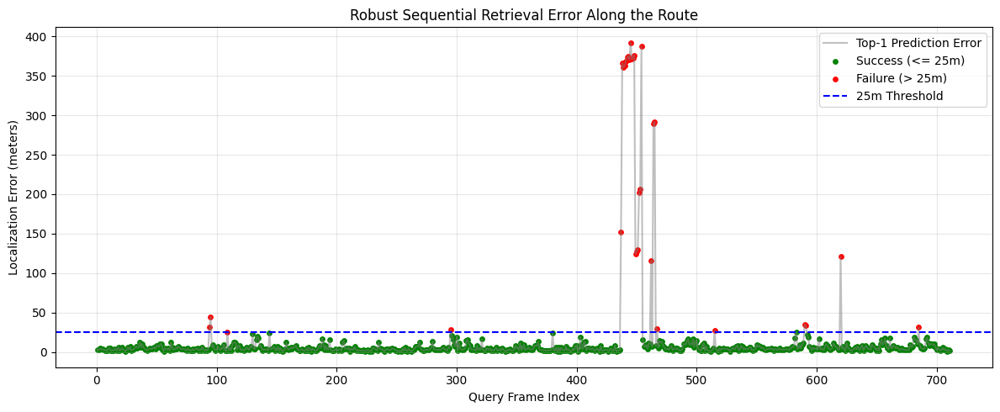

In [ ]:
# 1. Generate sequential timestamps for the query set (assuming 1 Hz capture rate)
num_queries = query_desc.size(0)
query_times = torch.arange(0, num_queries, dtype=torch.float32)

print(f"Loaded {db_desc.size(0)} pre-computed database representations.")
print(f"Loaded {num_queries} pre-computed query representations.")

chosen_start_frame = 0

# Pre-compute structural headings
db_headings = compute_trajectory_headings(db_coords)
query_headings = compute_trajectory_headings(query_coords)

# 2. Execute the Robust Finite-State Tracker
robust_sequential_recall = evaluate_robust_sequential_recall(
    db_descriptors=db_desc,
    db_coords=db_coords,
    db_headings=db_headings,
    query_headings=query_headings,
    query_descriptors=query_desc,
    query_coords=query_coords,
    query_timestamps=query_times,
    start_idx=chosen_start_frame,
    k_values=[1, 5, 10, 20],
    distance_threshold=10.0,
    max_velocity=15.0,
    entropy_threshold=0.55,       # Stricter confidence gate
    invalidation_patience=3       # Drops the anchor after 3 uncertain frames
)

print(f"\nRobust Sequential Retrieval Accuracy (Recall@K): {robust_sequential_recall}")


# 3. Replicate the error tracking loop to visualize along the route
start_idx = chosen_start_frame
max_k = 20
max_velocity = 15.0
entropy_threshold = 0.55
invalidation_patience = 3
distance_threshold = 25
temperature = 0.05

last_known_coord = query_coords[start_idx]
last_known_time = query_times[start_idx].item()
uncertainty_counter = 0

frame_indices = []
errors = []
successes = []
predicted_coords_x = []
predicted_coords_y = []

for i in range(start_idx + 1, num_queries):
    q_desc = query_desc[i].unsqueeze(0)
    q_coord = query_coords[i]
    q_time = query_times[i].item()

    similarity = torch.matmul(q_desc, db_desc.T).squeeze(0)

    # 1. Kinematic Bounding (Hard Veto)
    if last_known_coord is not None and last_known_time is not None:
        delta_t = q_time - last_known_time
        search_radius = max_velocity * delta_t
        db_distances_to_prior = torch.norm(db_coords - last_known_coord.unsqueeze(0), dim=1)
        out_of_bounds = db_distances_to_prior > search_radius
        similarity[out_of_bounds] = -1.0

    top_scores, topk_indices = torch.topk(similarity, k=max_k, largest=True)
    retrieved_coords = db_coords[topk_indices]

    # 2. Entropy Evaluation
    probs = F.softmax(top_scores / temperature, dim=0)
    entropy = -torch.sum(probs * torch.log(probs + 1e-8))
    norm_entropy = entropy / math.log(max_k)

    # 3. State Machine: Commit or Invalidate
    if norm_entropy.item() < entropy_threshold:
        last_known_coord = retrieved_coords[0]
        last_known_time = q_time
        uncertainty_counter = 0
    else:
        uncertainty_counter += 1
        if last_known_coord is not None:
            last_known_time = q_time

        if uncertainty_counter >= invalidation_patience:
            last_known_coord = None
            uncertainty_counter = 0

    # Track error
    error = torch.norm(retrieved_coords[0] - q_coord).item()
    frame_indices.append(i)
    errors.append(error)
    successes.append(error <= distance_threshold)
    predicted_coords_x.append(retrieved_coords[0, 0].item())
    predicted_coords_y.append(retrieved_coords[0, 1].item())

mean_error = np.mean(errors)
median_error = np.median(errors)
std_error = np.std(errors)
print(f"\nRetrieval Error Statistics:")
print(f"Mean Error:   {mean_error:.2f} m (± {std_error:.2f} m)")
print(f"Median Error: {median_error:.2f} m (± {std_error:.2f} m)\n")

# Plotting
plt.figure(figsize=(12, 5))
plt.plot(frame_indices, errors, color='gray', alpha=0.5, label='Top-1 Prediction Error')

succ_x = [frame_indices[j] for j, s in enumerate(successes) if s]
succ_y = [errors[j] for j, s in enumerate(successes) if s]
fail_x = [frame_indices[j] for j, s in enumerate(successes) if not s]
fail_y = [errors[j] for j, s in enumerate(successes) if not s]

plt.scatter(succ_x, succ_y, color='green', s=15, label=f'Success (<= {distance_threshold}m)')
plt.scatter(fail_x, fail_y, color='red', s=15, label=f'Failure (> {distance_threshold}m)')

plt.axhline(y=distance_threshold, color='blue', linestyle='--', label=f'{distance_threshold}m Threshold')
plt.xlabel('Query Frame Index')
plt.ylabel('Localization Error (meters)')
plt.title('Robust Sequential Retrieval Error Along the Route')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import pandas as pd
import math
import plotly.express as px

# --- Configuration ---
# Add your Mapbox access token (Make sure you regenerated it!)
mapbox_access_token = "ADD_TOKEN_HERE"
px.set_mapbox_access_token(mapbox_access_token)

# Inverse Equirectangular projection to convert local X, Y back to Lat, Lon
EARTH_RADIUS = 6378137.0
origin_lat_rad = math.radians(shared_origin[0])
origin_lon_rad = math.radians(shared_origin[1])

def convert_to_latlon(x_arr, y_arr):
    lat_rad = (y_arr / EARTH_RADIUS) + origin_lat_rad
    lon_rad = (x_arr / (EARTH_RADIUS * math.cos(origin_lat_rad))) + origin_lon_rad
    return np.degrees(lat_rad), np.degrees(lon_rad)

# 1. Successful Predictions
df_succ_pred = pd.DataFrame()
if len(succ_x) > 0:
    succ_pred_x = np.array([predicted_coords_x[j] for j, s in enumerate(successes) if s])
    succ_pred_y = np.array([predicted_coords_y[j] for j, s in enumerate(successes) if s])
    succ_lats, succ_lons = convert_to_latlon(succ_pred_x, succ_pred_y)
    df_succ_pred = pd.DataFrame({'lat': succ_lats, 'lon': succ_lons, 'Status': 'Predicted Success'})

# 2. Failed Predictions
df_fail_pred = pd.DataFrame()
if len(fail_x) > 0:
    fail_pred_x = np.array([predicted_coords_x[j] for j, s in enumerate(successes) if not s])
    fail_pred_y = np.array([predicted_coords_y[j] for j, s in enumerate(successes) if not s])
    fail_lats, fail_lons = convert_to_latlon(fail_pred_x, fail_pred_y)
    df_fail_pred = pd.DataFrame({'lat': fail_lats, 'lon': fail_lons, 'Status': 'Predicted Failure'})

# Combine into a single DataFrame for Plotly, excluding the True Query Path
df = pd.concat([df_succ_pred, df_fail_pred], ignore_index=True)

# Calculate dynamic center and zoom for the entire trajectory
min_lat, max_lat = df['lat'].min(), df['lat'].max()
min_lon, max_lon = df['lon'].min(), df['lon'].max()

center_lat = (min_lat + max_lat) / 2
center_lon = (min_lon + max_lon) / 2

# Heuristic zoom level (adjust as needed to fit the trajectory well)
dynamic_zoom = 15 # A slightly lower zoom to show a wider area

# Plot interactive map
fig = px.scatter_mapbox(
    df,
    lat="lat",
    lon="lon",
    color="Status",
    color_discrete_map={
        'Predicted Success': 'green',
        'Predicted Failure': 'red'
    },
    zoom=dynamic_zoom,
    center=dict(lat=center_lat, lon=center_lon),
    mapbox_style="dark",  # <--- Changed from "open-street-map" to "dark"
    title='Interactive Map: Localized Predictions'
)

# Adjust marker sizes and opacities for better visibility
fig.update_traces(marker=dict(size=8), selector=dict(name='Predicted Success'))
fig.update_traces(marker=dict(size=10), selector=dict(name='Predicted Failure'))

fig.update_layout(
    margin=dict(r=0, t=40, l=0, b=0),
    legend=dict(
        x=0.01, y=0.99,
        xanchor="left", yanchor="top",
        bgcolor="rgba(0,0,0,0.7)",
        bordercolor="white",
        borderwidth=1,
        font=dict(color="white")
    )
)
fig.show()

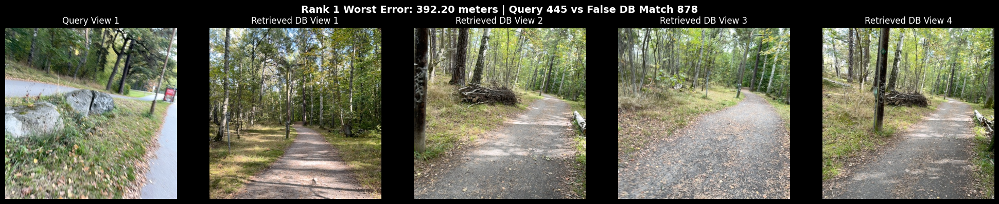

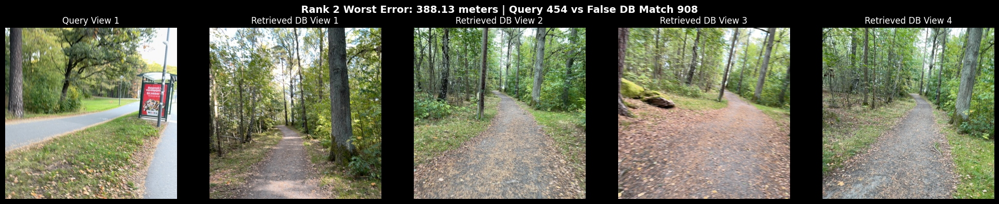

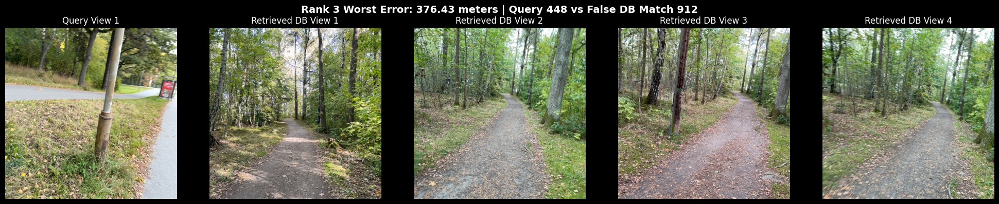

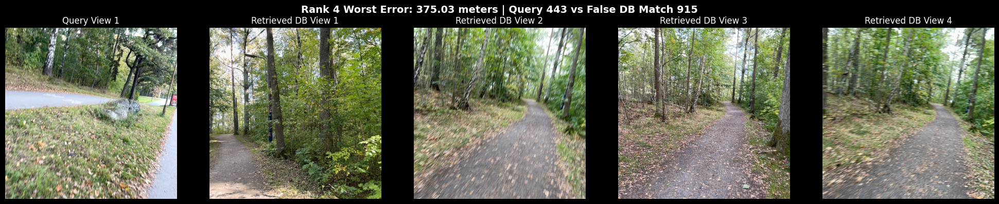

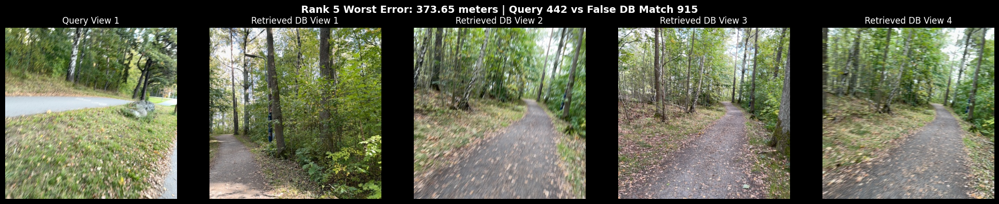

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# Reconstruct the recalled frame IDs from the saved predicted coordinates
recalled_frame_ids = []
db_xy = db_coords[:, :2].cpu()

for px, py in zip(predicted_coords_x, predicted_coords_y):
    pred_pt = torch.tensor([px, py], dtype=torch.float32)
    # Find the closest database point to the predicted coordinates to get its ID
    dists = torch.norm(db_xy - pred_pt.unsqueeze(0), dim=1)
    recalled_frame_ids.append(torch.argmin(dists).item())

# 1. Zip and sort the errors to find the top 5 worst predictions
error_data = list(zip(frame_indices, errors, recalled_frame_ids))
error_data.sort(key=lambda x: x[1], reverse=True)
top_5_errors = error_data[:5]

# 2. Iterate and plot
for rank, (q_idx, err, db_idx) in enumerate(top_5_errors):
    # Fetch query cluster (usually 1 frame for query dataset)
    q_rgb, _, _, _ = query_dataset[q_idx]
    q_S = q_rgb.shape[0]

    # Fetch falsely recalled database cluster (usually 4 frames)
    db_rgb, _, _, _ = db_dataset[db_idx]
    db_S = db_rgb.shape[0]

    total_cols = q_S + db_S

    # Set figure facecolor to black
    fig, axes = plt.subplots(1, total_cols, figsize=(4 * total_cols, 4), facecolor='black')

    # Set suptitle text color to white
    fig.suptitle(f"Rank {rank+1} Worst Error: {err:.2f} meters | Query {q_idx} vs False DB Match {db_idx}", fontsize=14, fontweight='bold', color='white')

    # Plot query frames
    for i in range(q_S):
        img = q_rgb[i].permute(1, 2, 0).cpu().numpy()
        axes[i].imshow(img)
        # Set title text color to white
        axes[i].set_title(f"Query View {i+1}", color='white')
        axes[i].axis('off')
        # Add a border to highlight the query
        for spine in axes[i].spines.values():
            spine.set_edgecolor('blue')
            spine.set_linewidth(3)

    # Plot retrieved database frames
    for i in range(db_S):
        img = db_rgb[i].permute(1, 2, 0).cpu().numpy()
        ax_idx = q_S + i
        axes[ax_idx].imshow(img)
        # Set title text color to white
        axes[ax_idx].set_title(f"Retrieved DB View {i+1}", color='white')
        axes[ax_idx].axis('off')
        # Add a border to highlight the false DB match
        for spine in axes[ax_idx].spines.values():
            spine.set_edgecolor('red')
            spine.set_linewidth(3)

    plt.tight_layout()
    plt.show()

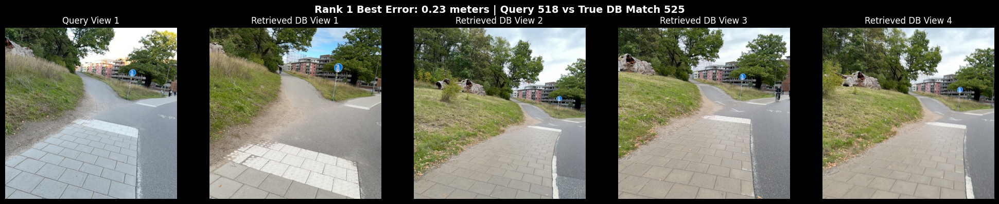

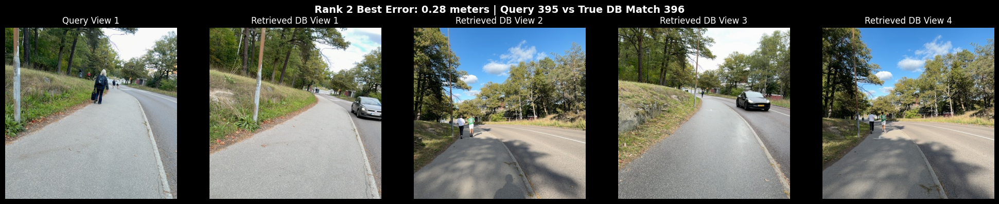

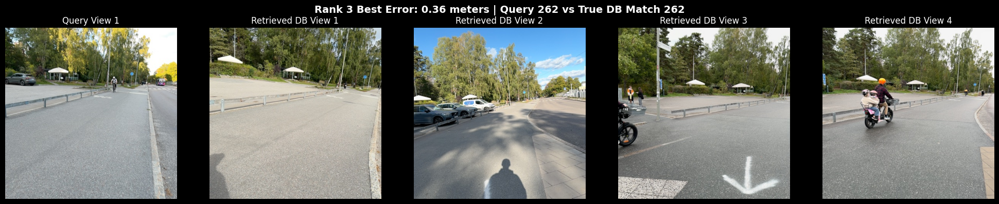

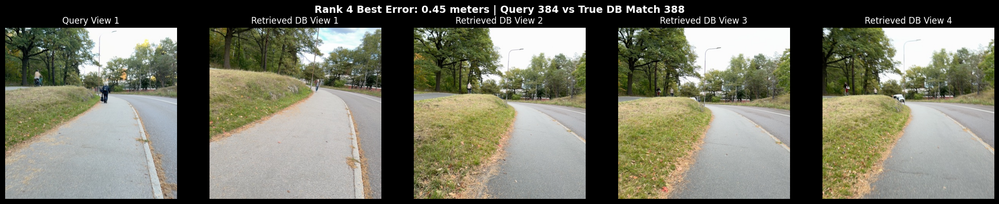

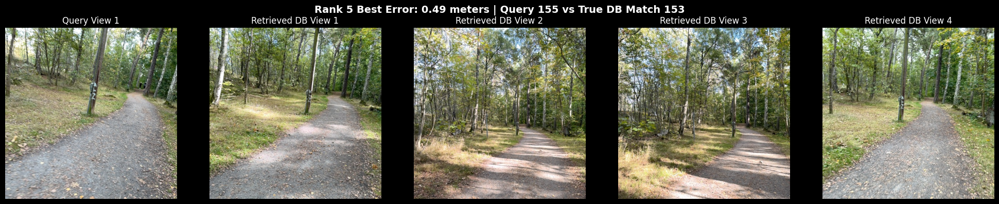

In [ ]:

# Reconstruct the recalled frame IDs from the saved predicted coordinates
recalled_frame_ids = []
db_xy = db_coords[:, :2].cpu()

for px, py in zip(predicted_coords_x, predicted_coords_y):
    pred_pt = torch.tensor([px, py], dtype=torch.float32)
    # Find the closest database point to the predicted coordinates to get its ID
    dists = torch.norm(db_xy - pred_pt.unsqueeze(0), dim=1)
    recalled_frame_ids.append(torch.argmin(dists).item())

# 1. Zip and sort the errors to find the top 5 best predictions (lowest error)
error_data = list(zip(frame_indices, errors, recalled_frame_ids))

# Sort ascending for Top 5 Best
error_data.sort(key=lambda x: x[1], reverse=False)
top_5_best = error_data[:5]

# 2. Iterate and plot
for rank, (q_idx, err, db_idx) in enumerate(top_5_best):
    # Fetch query cluster (usually 1 frame for query dataset)
    q_rgb, _, _, _ = query_dataset[q_idx]
    q_S = q_rgb.shape[0]

    # Fetch recalled database cluster (4 frames per cluster)
    # db_idx is the flattened frame index; divide by 4 to get the cluster index
    cluster_idx = db_idx // 4
    db_rgb, _, _, _ = db_dataset[cluster_idx]
    db_S = db_rgb.shape[0]

    total_cols = q_S + db_S

    # Set figure facecolor to black
    fig, axes = plt.subplots(1, total_cols, figsize=(4 * total_cols, 4), facecolor='black')

    # Set suptitle text color to white
    fig.suptitle(f"Rank {rank+1} Best Error: {err:.2f} meters | Query {q_idx} vs True DB Match {cluster_idx}", fontsize=14, fontweight='bold', color='white')

    # Plot query frames
    for i in range(q_S):
        img = q_rgb[i].permute(1, 2, 0).cpu().numpy()
        axes[i].imshow(img)
        # Set title text color to white
        axes[i].set_title(f"Query View {i+1}", color='white')
        axes[i].axis('off')
        # Add a border to highlight the query
        for spine in axes[i].spines.values():
            spine.set_edgecolor('blue')
            spine.set_linewidth(3)

    # Plot retrieved database frames
    for i in range(db_S):
        img = db_rgb[i].permute(1, 2, 0).cpu().numpy()
        ax_idx = q_S + i
        axes[ax_idx].imshow(img)
        # Set title text color to white
        axes[ax_idx].set_title(f"Retrieved DB View {i+1}", color='white')
        axes[ax_idx].axis('off')
        # Add a border to highlight the DB match
        for spine in axes[ax_idx].spines.values():
            spine.set_edgecolor('green')
            spine.set_linewidth(3)

    plt.tight_layout()
    plt.show()
